In [1]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import csv
from pathlib import Path

In [2]:
dataset_path = "../dataset"
classes = os.listdir(dataset_path)

print(classes)
for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    images = os.listdir(class_path)

    print(class_name, ":", len(images))

['bacterial_leaf_blight', 'brown_spot', 'healthy', 'rice_blast', 'tungro_disease']
bacterial_leaf_blight : 1659
brown_spot : 1659
healthy : 1659
rice_blast : 1659
tungro_disease : 1659


In [3]:
def resize_with_padding(image, target_size=128):

    # Convert image to RGBA
    image = image.convert("RGBA")

    # Create a black background
    background = Image.new(
        "RGBA",
        image.size,
        (0, 0, 0, 255)
    )

    # Combine image with background
    image = Image.alpha_composite(background, image)

    # Convert to RGB
    image = image.convert("RGB")
    
    # Get original dimensions
    original_width, original_height = image.size

    # Calculate scaling factor
    scale = min(
        target_size / original_width,
        target_size / original_height
    )

    # Calculate new dimensions
    new_width = int(original_width * scale)
    new_height = int(original_height * scale)

    # Resize image
    resized_image = image.resize(
        (new_width, new_height),
        Image.Resampling.LANCZOS
    )

    # Create background
    padded_image = Image.new(
        "RGB",
        (target_size, target_size),
        (0, 0, 0)
    )

    # Calculate center position
    x_offset = (target_size - new_width) // 2
    y_offset = (target_size - new_height) // 2

    # Paste resized image
    padded_image.paste(
        resized_image,
        (x_offset, y_offset)
    )

    return padded_image

In [4]:
class_name = classes[2]  # Select the first class for testing
image_name = "1.jpg"

image_path = os.path.join(dataset_path, class_name, image_name)

original_image = Image.open(image_path).convert("RGB")
test_image = resize_with_padding(original_image)

print("Original:", original_image.size)
print("Processed:", test_image.size)

Original: (1600, 1200)
Processed: (128, 128)


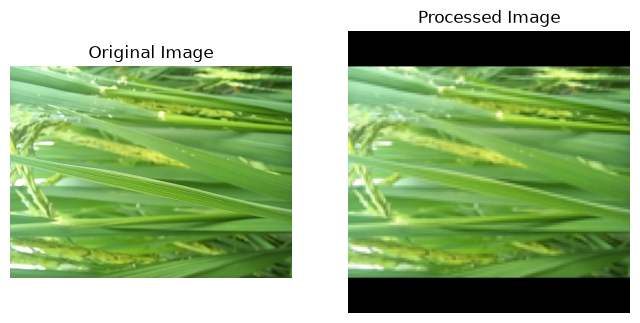

In [5]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(test_image)
plt.title("Processed Image")
plt.axis("off")

plt.show()

In [6]:
output_path = "../processed_dataset"

os.makedirs(output_path, exist_ok=True)

print("Output folder created!")

Output folder created!


In [7]:
# Resizing and saving images with padding
for class_name in classes:
    class_output_path = os.path.join(output_path, class_name)
    os.makedirs(class_output_path, exist_ok=True)


    folder_path = os.path.join(dataset_path, class_name)

    image_files = [
        file for file in os.listdir(folder_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    for file_name in image_files:

        image_path = os.path.join(folder_path, file_name)

        with Image.open(image_path) as image:

            processed_image = resize_with_padding(image)

            output_file = os.path.splitext(file_name)[0] + ".jpg"

            save_path = os.path.join(class_output_path, output_file)

            processed_image.save(save_path, quality=95)

    print(f"The class {class_name} processing completed!")
    print("Images processed:", len(image_files))

The class bacterial_leaf_blight processing completed!
Images processed: 1659
The class brown_spot processing completed!
Images processed: 1659
The class healthy processing completed!
Images processed: 1659
The class rice_blast processing completed!
Images processed: 1659
The class tungro_disease processing completed!
Images processed: 1659


In [8]:
# Load one processed image
image_path = "../processed_dataset/healthy"

image_files = os.listdir(image_path)
test_image = Image.open(
    os.path.join(image_path, image_files[0])
)

# Convert image to NumPy array
image_array = np.array(test_image)

# Inspect image information
print("Shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel:", image_array.min())
print("Maximum pixel:", image_array.max())

Shape: (128, 128, 3)
Data type: uint8
Minimum pixel: 0
Maximum pixel: 255
